# 경사하강법·일반화

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## 같은 함수, 다른 학습률

f(w)=(w−3)², 초기값 0에서 학습률 0.1·0.9·1.1을 비교하시오. 진동과 발산을 구분하시오.

0.1 2.988666320441113
0.9 3.011333679558887
1.1 289.188649932208


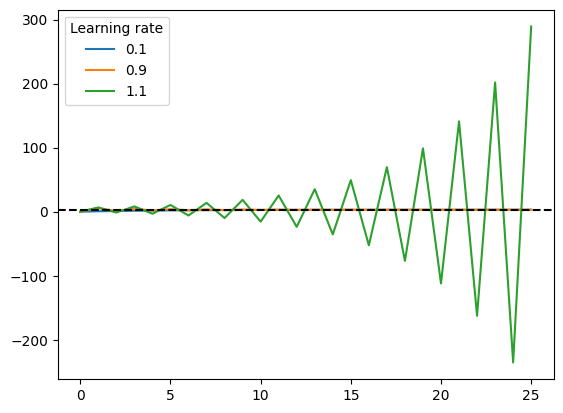

In [2]:
def descent(lr,steps=25):
    w=0.; history=[w]
    for _ in range(steps):
        w -= lr*2*(w-3); history.append(w)
    return np.array(history)
for lr in [.1,.9,1.1]:
    history=descent(lr);plt.plot(history,label=str(lr));print(lr,history[-1])
plt.axhline(3,color='k',ls='--');plt.legend(title='Learning rate');plt.show()

## 당뇨병 자료의 한 변수 회귀

설명변수 BMI, 목표변수는 1년 뒤 질병 진행도이다. 훈련·시험 자료를 먼저 나누고 훈련 자료로만 평균·표준편차를 구하시오. 평균제곱오차의 절반을 손실로 사용하여 기울기를 확인하시오.

직접 구현: 47.14112176124699 153.73654390934556 라이브러리: 47.14112176124785 153.73654390934846
시험 MSE: 4061.82592849491


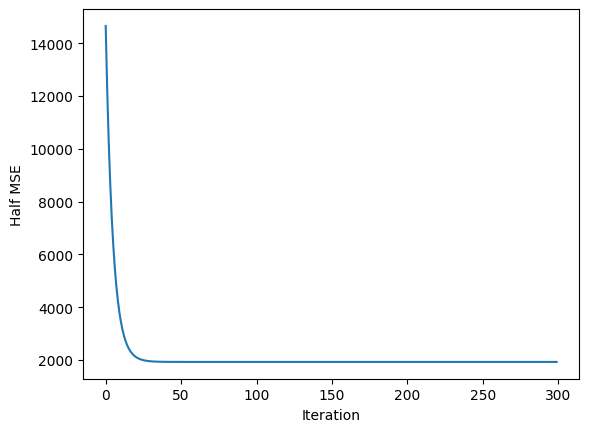

In [3]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
data = load_diabetes()
xtr, xte, ytr, yte = train_test_split(data.data[:,2],data.target,test_size=.2,random_state=42)
mu,sd = xtr.mean(),xtr.std()
z=(xtr-mu)/sd; ztest=(xte-mu)/sd
w,b = 1.,1.;lr=.1;loss=[]
for _ in range(300):
    error=w*z+b-ytr
    loss.append(np.mean(error**2)/2)
    dw=np.mean(error*z);db=error.mean()
    w-=lr*dw;b-=lr*db
reference=LinearRegression().fit(z[:,None],ytr)
print('직접 구현:',w,b,'라이브러리:',reference.coef_[0],reference.intercept_)
print('시험 MSE:',mean_squared_error(yte,w*ztest+b))
assert np.allclose([w,b],[reference.coef_[0],reference.intercept_],atol=1e-8)
plt.plot(loss);plt.xlabel('Iteration');plt.ylabel('Half MSE');plt.show()

## 데이터 누출

시험 자료를 평균·표준편차 계산에 포함하면 왜 문제가 되는지 설명하시오. 훈련 오차가 작다는 사실만으로 새 관측의 오차도 작다고 말할 수 있는지 설명하시오.

같은 표본에서 반복 계산하는 횟수와 관측 자료의 개수를 구분. 분석 목적·평가지표·시험 자료 사용 시점을 먼저 결정